# Preprocessing and machine learning trained classificator for pacient diagnosis


```
Genera el código completo de una Jupyter Notebook (.ipynb) diseñada para ejecutarse en Google Colaboratory. La notebook debe implementar un flujo de Machine Learning que descargue, preprocese y clasifique historias clínicas en español.

Debe cumplir estrictamente con los siguientes requisitos:
Datos: Utilizar los textos del corpus SPACCC_MEDDOCAN (https://github.com/PlanTL-GOB-ES/SPACCC_MEDDOCAN/tree/master/corpus/dev/brat) y las etiquetas de codificación de diagnósticos de CodiEsp (https://zenodo.org/records/3837305).
Pipeline: Implementar la extracción de características usando CountVectorizer de scikit-learn y entrenar un modelo clasificador sobre los códigos CodiEsp.
Formato: Entrega el resultado exclusivamente como el código fuente estructurado de una notebook (.ipynb), combinando celdas de documentación (Markdown) y celdas de código de Python listas para su uso. No compiles ni ejecutes el código.
```



## OBJETIVO

La tarea que vamos a abordar es un **problema de clasificación de texto multilabel: dado un texto, asignarle uno o más códigos CIE-10** (clasificacion internacional de enfermedades). La dificultad principal es que existen miles de códigos posibles (más de 10.000 en CIE-10-ES) y un documento puede tener varios simultáneamente.

# Clasificador de Enfermedades en Historias Clínicas (CodiEsp / CIE-10)

Este notebook implementa un pipeline de clasificación automática de códigos CIE-10 (ICD-10) sobre historias clínicas en español, usando:

- **Corpus de textos**: SPACCC/MEDDOCAN (formato BRAT, archivos `.txt`) — [GitHub](https://github.com/PlanTL-GOB-ES/SPACCC_MEDDOCAN/tree/master/corpus/dev/brat)
- **Etiquetas (códigos CIE-10)**: CodiEsp corpus — [Zenodo](https://zenodo.org/records/3837305)
- **Vectorización**: `CountVectorizer` de scikit-learn
- **Clasificación**: `LinearSVC` con estrategia MultiLabel (One-vs-Rest)

---
**Flujo general:**
1. Descarga de datos (MEDDOCAN y CodiEsp)
2. Carga y preprocesamiento de textos `.txt`
3. Carga de anotaciones CodiEsp (TSV con `articleID` → `ICD10-code`)
4. Alineación de documentos comunes entre ambos recursos: uno tiene las historicas clinicas (MEDDOCAN) y el otro las enfermedades (Codi), hay que     generar un dataframe combinado y luego vectorizarlo.
5. Vectorización con `CountVectorizer`
6. Entrenamiento del clasificador multilabel
7. Evaluación del modelo
8. Predicción sobre nuevos textos

Los modelos de Machine Learning (como las redes neuronales o los vectores de soporte) no entienden el idioma español; solo entienden de matrices y matemáticas.
CountVectorizer se encarga de hacer esa traducción usando el modelo Bolsa de Palabras (Bag of Words). ¿Cómo funciona? Crea un vocabulario gigante con todas las palabras únicas que existen en tus historias clínicas. Luego, transforma cada documento en un vector de números (un array), donde cada posición representa una palabra del vocabulario y el número indica cuántas veces aparece esa palabra en ese texto en particular.

LinearSVC significa Linear Support Vector Classification (Clasificador de Vectores de Soporte Lineal). Es uno de los algoritmos tradicionales más potentes para texto. ¿Cómo funciona? Intenta dibujar una línea geométrica (un hiperplano) en el espacio multidimensional para separar los textos que tienen una enfermedad de los que no la tienen.

## 0. Instalación de dependencias

In [1]:
!pip install scikit-learn pandas numpy matplotlib seaborn requests tqdm -q

## 1. Descarga de los recursos

### 1.1 SPACCC/MEDDOCAN — corpus de historias clínicas (subset `dev`, formato BRAT)

Los archivos `.txt` contienen el cuerpo de las historias clínicas en español.
Los archivos `.ann` contienen las anotaciones de entidades (no se usan en este pipeline).

> Fuente: https://github.com/PlanTL-GOB-ES/SPACCC_MEDDOCAN

In [2]:
import os
import zipfile
import requests
import shutil  # <-- Nueva librería para borrar carpetas completas
from tqdm import tqdm

MEDDOCAN_ZIP_URL = "https://github.com/PlanTL-GOB-ES/SPACCC_MEDDOCAN/archive/refs/heads/master.zip"
MEDDOCAN_ZIP_PATH = "SPACCC_MEDDOCAN.zip"
MEDDOCAN_EXTRACT_DIR = "SPACCC_MEDDOCAN"

MEDDOCAN_BRAT_DIR = os.path.join(MEDDOCAN_EXTRACT_DIR, "SPACCC_MEDDOCAN-master", "corpus", "dev", "brat")

# ── 1. Descarga ─────────────────────────────────────────────────────────────
if not os.path.exists(MEDDOCAN_ZIP_PATH):
    print("Descargando SPACCC_MEDDOCAN...")
    r = requests.get(MEDDOCAN_ZIP_URL, stream=True)
    total = int(r.headers.get('content-length', 0))
    with open(MEDDOCAN_ZIP_PATH, 'wb') as f, tqdm(total=total, unit='B', unit_scale=True) as bar:
        for chunk in r.iter_content(chunk_size=8192):
            f.write(chunk)
            bar.update(len(chunk))
    print("Descarga completada.")

    # ¡ESTA ES LA CLAVE! Si descargamos un ZIP nuevo, borramos la carpeta vieja si existía
    if os.path.exists(MEDDOCAN_EXTRACT_DIR):
        shutil.rmtree(MEDDOCAN_EXTRACT_DIR)
else:
    print("ZIP de MEDDOCAN ya existe, omitiendo descarga.")

# ── 2. Extracción Forzada ───────────────────────────────────────────────────
if not os.path.exists(MEDDOCAN_EXTRACT_DIR) or not os.path.exists(MEDDOCAN_BRAT_DIR):
    print("Extrayendo SPACCC_MEDDOCAN...")
    with zipfile.ZipFile(MEDDOCAN_ZIP_PATH, 'r') as z:
        z.extractall(MEDDOCAN_EXTRACT_DIR)
    print("Extracción completada.")
else:
    print("El directorio completo ya existe, omitiendo extracción.")

# ── 3. Verificar contenido ──────────────────────────────────────────────────
txt_files = [f for f in os.listdir(MEDDOCAN_BRAT_DIR) if f.endswith('.txt')]
print(f"\nArchivos .txt encontrados en dev/brat: {len(txt_files)}")
print("Ejemplo:", txt_files[:3])

Descargando SPACCC_MEDDOCAN...


16.2MB [00:00, 16.9MB/s]


Descarga completada.
Extrayendo SPACCC_MEDDOCAN...
Extracción completada.

Archivos .txt encontrados en dev/brat: 250
Ejemplo: ['S1698-44472005000400012-1.txt', 'S0378-48352005000500005-1.txt', 'S0210-48062006000200018-1.txt']


### 1.2 CodiEsp — etiquetas CIE-10

El corpus CodiEsp contiene los mismos documentos del SPACCC anotados con códigos CIE-10 (diagnóstico y procedimiento).
Usaremos el subtrack **CodiEsp-D** (diagnóstico).

> Fuente: https://zenodo.org/records/3837305

In [4]:
CODIESP_ZIP_URL = "https://zenodo.org/records/3837305/files/codiesp.zip?download=1"
CODIESP_ZIP_PATH = "codiesp.zip"
CODIESP_EXTRACT_DIR = "codiesp"

if not os.path.exists(CODIESP_ZIP_PATH):
    print("Descargando CodiEsp corpus...")
    r = requests.get(CODIESP_ZIP_URL, stream=True)
    total = int(r.headers.get('content-length', 0))
    with open(CODIESP_ZIP_PATH, 'wb') as f, tqdm(total=total, unit='B', unit_scale=True) as bar:
        for chunk in r.iter_content(chunk_size=8192):
            f.write(chunk)
            bar.update(len(chunk))
    print("Descarga completada.")
else:
    print("ZIP de CodiEsp ya existe, omitiendo descarga.")

if not os.path.exists(CODIESP_EXTRACT_DIR):
    print("Extrayendo CodiEsp...")
    with zipfile.ZipFile(CODIESP_ZIP_PATH, 'r') as z:
        z.extractall(CODIESP_EXTRACT_DIR)
    print("Extracción completada.")
else:
    print("Directorio CodiEsp ya existe, omitiendo extracción.")

# Inspeccionar estructura
for root, dirs, files in os.walk(CODIESP_EXTRACT_DIR):
    level = root.replace(CODIESP_EXTRACT_DIR, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level < 3:
        subindent = ' ' * 2 * (level + 1)
        for f in files[:5]:
            print(f'{subindent}{f}')
        if len(files) > 5:
            print(f'{subindent}... y {len(files)-5} archivos más')

ZIP de CodiEsp ya existe, omitiendo descarga.
Directorio CodiEsp ya existe, omitiendo extracción.
codiesp/
  final_dataset_v4_to_publish/
    README.txt
    dev/
      devX.tsv
      devP.tsv
      devD.tsv
      text_files/
      text_files_en/
    background/
      text_files/
      text_files_en/
    train/
      trainD.tsv
      trainX.tsv
      trainP.tsv
      text_files/
      text_files_en/
    test/
      testX.tsv
      testP.tsv
      testD.tsv
      text_files/
      text_files_en/


## 2. Carga de textos del corpus MEDDOCAN

Cada archivo `.txt` en `dev/brat` es una historia clínica. El nombre del archivo (sin extensión) es el `articleID`.

In [5]:
import pandas as pd

def cargar_textos_brat(directorio):
    """Carga todos los archivos .txt de un directorio BRAT.
    Retorna un DataFrame con columnas: articleID, texto.
    """
    registros = []
    for nombre_archivo in sorted(os.listdir(directorio)):
        if nombre_archivo.endswith('.txt'):
            article_id = nombre_archivo.replace('.txt', '')
            ruta = os.path.join(directorio, nombre_archivo)
            with open(ruta, 'r', encoding='utf-8') as f:
                texto = f.read().strip()
            registros.append({'articleID': article_id, 'texto': texto})
    return pd.DataFrame(registros)

df_textos = cargar_textos_brat(MEDDOCAN_BRAT_DIR)

print(f"Historias clínicas cargadas: {len(df_textos)}")
print("\nPrimeros registros:")
df_textos.head(3)

Historias clínicas cargadas: 250

Primeros registros:


,articleID,texto
0,S0004-06142006000500012-1,Datos del paciente.\nNombre: Pedro.\nApellido...
1,S0004-06142006000600012-1,Datos del paciente.\nNombre: Mariano.\nApelli...
2,S0004-06142006000600015-1,﻿Nombre: Marc.\nApellidos: Garcia Prieto.\nCI...


In [6]:
# Visualizar un ejemplo de historia clínica
print("=== Ejemplo de historia clínica ===")
print(f"ID: {df_textos.iloc[0]['articleID']}")
print("─" * 60)
print(df_textos.iloc[0]['texto'][:800], "...")

=== Ejemplo de historia clínica ===
ID: S0004-06142006000500012-1
────────────────────────────────────────────────────────────
Datos del paciente.
Nombre:  Pedro.
Apellidos: De Miguel Rivera.
NHC: 2569870.
Domicilio: Calle Carmen Romero, 23, 1D.
Localidad/ Provincia: Madrid.
CP: 28035.
Datos asistenciales.
Fecha de nacimiento: 10/10/1963.
País: España.
Edad: 53 años Sexo: H.
Fecha de Ingreso: 17/06/2016.
Médico: Estefanía Romero Selas  NºCol: 28 28 20943.
Informe clínico del paciente: varón de 53 años sin antecedentes de interés que ingresa procedente de urgencias con un cuadro de tromboembolismo pulmonar.
Ante la sospecha de neoplasia oculta y la presencia de hematuria no evidenciada previamente se procede a la realización de Ecografía abdominal donde se evidencia una masa renal derecha y se completa el estudio con TAC y RM..
Ambos estudios confirman la presencia de una tumoración heterogénea que infiltra los dos ...


## 3. Carga de etiquetas CodiEsp (CIE-10)

El corpus CodiEsp usa los mismos documentos que SPACCC. El subtrack **CodiEsp-D** (diagnóstico) tiene un TSV con:
```
articleID \t ICD10-code
```
Un mismo documento puede tener **múltiples códigos** → clasificación **multilabel**.

Usaremos los archivos de **train** y **dev** de CodiEsp para training y evaluación.

En pocas palabras, este código hace dos cosas principales:

Busca automáticamente tanto los de entrenamiento o train como los de validación o dev) usando patrones de texto en sus nombres. Carga y consolida los datos con Pandas, tomando los registros y agrupando todos los códigos médicos de un mismo paciente en una sola lista, ya que una historia clínica puede tener múltiples diagnósticos a la vez. El resultado final es una tabla limpia donde cada fila representa un documento único con su identificador y su lista completa de códigos CIE asignados.

In [7]:
import os
import glob
import pandas as pd

# 1. Definimos la función de carga original
def cargar_etiquetas_codiesp(ruta_tsv):
    """Carga el archivo TSV de CodiEsp-D y agrupa códigos por documento."""
    df = pd.read_csv(ruta_tsv, sep='\t', header=None,
                     names=['articleID', 'codigo'],
                     dtype=str)
    df['articleID'] = df['articleID'].str.strip()
    df['codigo'] = df['codigo'].str.strip().str.upper()

    df_agrupado = df.groupby('articleID')['codigo'].apply(list).reset_index()
    df_agrupado.columns = ['articleID', 'codigos']
    return df_agrupado

# ── 2. Inicializamos las variables de ruta como vacías (None)
tsv_train = None
tsv_dev = None

# Definí acá el nombre de la carpeta raíz donde extrajiste CodiEsp
CODIESP_EXTRACT_DIR = "codiesp"  # O la ruta que estés usando

# ── 3. Tu código de búsqueda: Escaneamos el disco dinámicamente
tsv_files = glob.glob(os.path.join(CODIESP_EXTRACT_DIR, '**', '*.tsv'), recursive=True)

# Asignamos automáticamente las rutas según el nombre del archivo
for f in sorted(tsv_files):
    nombre = os.path.basename(f).lower()
    if 'train' in nombre and 'd.tsv' in nombre:
        tsv_train = f
    elif 'dev' in nombre and 'd.tsv' in nombre:
        tsv_dev = f

# ── 4. Control de seguridad por si glob no encuentra nada
if tsv_train is None or tsv_dev is None:
    raise FileNotFoundError(
        f"No se pudieron mapear los archivos automáticos. "
        f"Archivos encontrados en el disco: {tsv_files}"
    )

print(f"🎯 Detectado automáticamente Train: {tsv_train}")
print(f"🎯 Detectado automáticamente Dev:   {tsv_dev}\n")

# ── 5. Procesamos con Pandas
df_labels_train = cargar_etiquetas_codiesp(tsv_train)
df_labels_dev   = cargar_etiquetas_codiesp(tsv_dev)

print(f"✅ Documentos con etiquetas (train): {len(df_labels_train)}")
print(f"✅ Documentos con etiquetas (dev):   {len(df_labels_dev)}")
df_labels_train.head()

🎯 Detectado automáticamente Train: codiesp/final_dataset_v4_to_publish/train/trainD.tsv
🎯 Detectado automáticamente Dev:   codiesp/final_dataset_v4_to_publish/dev/devD.tsv

✅ Documentos con etiquetas (train): 500
✅ Documentos con etiquetas (dev):   250


,articleID,codigos
0,S0004-06142005000700014-1,"[N44.8, Z20.818, R60.9, R52, A23.9, I83.90, I8..."
1,S0004-06142005000900013-1,"[D30.3, R58]"
2,S0004-06142005000900015-1,"[R19.00, N50.9, D49.59, R63.4, R52, N50.89, C6..."
3,S0004-06142005001000011-3,"[G82.21, G71.8, R53.81, Z98.85, G04.1, R20.1, ..."
4,S0004-06142005001000016-1,"[N32.0, K40.90, N32.89]"


Esa tabla representa el nuevo dataframe que mergea MEDDICAN y Codi.

## 4. Carga de textos del corpus CodiEsp

CodiEsp incluye sus propios archivos de texto en `text_files/`. Usaremos esos en lugar del subset MEDDOCAN-dev cuando corresponda, ya que las etiquetas están indexadas por los IDs de CodiEsp.

In [8]:
def cargar_textos_directorio(directorio):
    """Carga archivos .txt de un directorio."""
    registros = []
    if not os.path.exists(directorio):
        print(f"ADVERTENCIA: directorio no encontrado: {directorio}")
        return pd.DataFrame(columns=['articleID', 'texto'])
    for nombre_archivo in sorted(os.listdir(directorio)):
        if nombre_archivo.endswith('.txt'):
            article_id = nombre_archivo.replace('.txt', '')
            ruta = os.path.join(directorio, nombre_archivo)
            with open(ruta, 'r', encoding='utf-8') as f:
                texto = f.read().strip()
            registros.append({'articleID': article_id, 'texto': texto})
    return pd.DataFrame(registros)

# Buscar directorios text_files dentro de CodiEsp
text_dirs = glob.glob(os.path.join(CODIESP_EXTRACT_DIR, '**', 'text_files'), recursive=True)
print("Directorios text_files encontrados:")
for d in sorted(text_dirs):
    print(" ", d)

# Identificar train y dev
dir_train_txt = None
dir_dev_txt   = None

for d in sorted(text_dirs):
    partes = d.lower().replace('\\', '/').split('/')
    if 'train' in partes and 'text_files' in partes and dir_train_txt is None:
        dir_train_txt = d
    elif 'dev' in partes and 'text_files' in partes and dir_dev_txt is None:
        dir_dev_txt = d

print(f"\nDirectorio textos train: {dir_train_txt}")
print(f"Directorio textos dev:   {dir_dev_txt}")

df_texts_train = cargar_textos_directorio(dir_train_txt)
df_texts_dev   = cargar_textos_directorio(dir_dev_txt)

print(f"\nTextos cargados (train): {len(df_texts_train)}")
print(f"Textos cargados (dev):   {len(df_texts_dev)}")

Directorios text_files encontrados:
  codiesp/final_dataset_v4_to_publish/background/text_files
  codiesp/final_dataset_v4_to_publish/dev/text_files
  codiesp/final_dataset_v4_to_publish/test/text_files
  codiesp/final_dataset_v4_to_publish/train/text_files

Directorio textos train: codiesp/final_dataset_v4_to_publish/train/text_files
Directorio textos dev:   codiesp/final_dataset_v4_to_publish/dev/text_files

Textos cargados (train): 500
Textos cargados (dev):   250


In [ ]:
df_texts_train

,articleID,texto
0,S0004-06142005000700014-1,Describimos el caso de un varón de 37 años con...
1,S0004-06142005000900013-1,Se trata de una mujer de 29 años sometida a un...
2,S0004-06142005000900015-1,"Varón de 36 años, sin antecedentes de interés,..."
3,S0004-06142005001000011-3,Mujer de 42 años en el momento de someterse a ...
4,S0004-06142005001000016-1,Varón de 65 años que consultaba por un síndrom...
...,...,...
495,S1889-836X2015000200005-1,Describimos el caso de una paciente de 47 años...
496,S1889-836X2016000100006-1,Paciente varón de 65 años diagnosticado de OI ...
497,S2254-28842012000300010-1,Varón de 72 años en programa de HD desde dicie...
498,S2254-28842014000200009-1,"Mujer de 33 años, que llega a urgencias con un..."


## 5. Alineación de textos y etiquetas

In [9]:
# Join textos + etiquetas para train
df_train = pd.merge(df_texts_train, df_labels_train, on='articleID', how='inner')
df_dev   = pd.merge(df_texts_dev,   df_labels_dev,   on='articleID', how='inner')

print(f"Documentos en split train (texto + etiquetas): {len(df_train)}")
print(f"Documentos en split dev   (texto + etiquetas): {len(df_dev)}")

# Estadísticas de etiquetas
n_codigos_por_doc = df_train['codigos'].apply(len)
print(f"\nCódigos por documento (train):")
print(f"  Mínimo:  {n_codigos_por_doc.min()}")
print(f"  Máximo:  {n_codigos_por_doc.max()}")
print(f"  Media:   {n_codigos_por_doc.mean():.2f}")

df_train.head(3)

Documentos en split train (texto + etiquetas): 500
Documentos en split dev   (texto + etiquetas): 250

Códigos por documento (train):
  Mínimo:  1
  Máximo:  40
  Media:   11.28


,articleID,texto,codigos
0,S0004-06142005000700014-1,Describimos el caso de un varón de 37 años con...,"[N44.8, Z20.818, R60.9, R52, A23.9, I83.90, I8..."
1,S0004-06142005000900013-1,Se trata de una mujer de 29 años sometida a un...,"[D30.3, R58]"
2,S0004-06142005000900015-1,"Varón de 36 años, sin antecedentes de interés,...","[R19.00, N50.9, D49.59, R63.4, R52, N50.89, C6..."


articleID: El código único de la historia clínica (funciona como tu llave o clave primaria).
texto: El texto libre y sucio que escribe el médico (aquí es donde aplicarás el CountVectorizer para convertirlo en números).
codigos: La lista objetivo (tu Target o $Y$).
En promedio cada historia clinica tiene 11-12 diagnosticos de enfermedad.

Códigos únicos en train: 1767

Top 20 códigos más frecuentes:
  R52: 112
  R69: 99
  R50.9: 97
  I10: 77
  R60.9: 66
  R59.9: 65
  R53.1: 57
  R11.10: 47
  R59.0: 46
  R10.9: 46
  R58: 45
  B99.9: 45
  D64.9: 43
  E11.9: 41
  I96: 37
  R63.4: 34
  R31.9: 34
  N28.9: 30
  B20: 30
  L53.9: 30


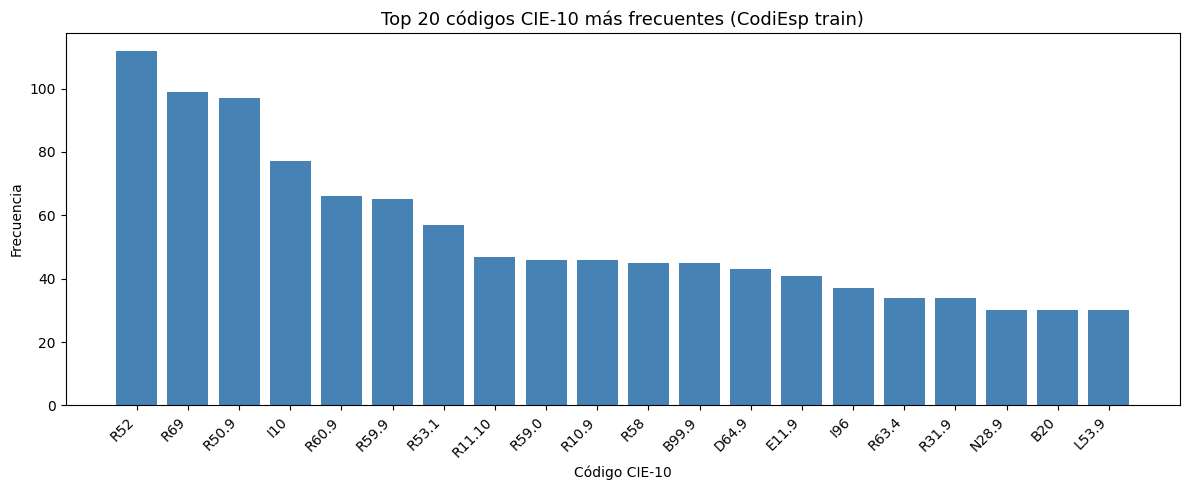

In [10]:
from collections import Counter
import matplotlib.pyplot as plt

# Códigos más frecuentes
todos_codigos = [c for lista in df_train['codigos'] for c in lista]
conteo = Counter(todos_codigos)
print(f"Códigos únicos en train: {len(conteo)}")
print("\nTop 20 códigos más frecuentes:")
for codigo, freq in conteo.most_common(20):
    print(f"  {codigo}: {freq}")

# Gráfico
top_n = 20
top_items = conteo.most_common(top_n)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar([x[0] for x in top_items], [x[1] for x in top_items], color='steelblue')
ax.set_title(f'Top {top_n} códigos CIE-10 más frecuentes (CodiEsp train)', fontsize=13)
ax.set_xlabel('Código CIE-10')
ax.set_ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 6. Preprocesamiento de texto

- Minúsculas: reduce la dimensionalidad del vocabulario. 'Diabetes' y 'diabetes' son la misma palabra.
- Eliminación de números: valores como '67 años' o 'V1-V4' son sustituidos por espacios. En textos clínicos los números son frecuentes pero raramente aportan información de diagnóstico.
- Limpieza de caracteres especiales: se conservan letras del español (incluyendo acentos y ñ) y se eliminan signos de puntuación, símbolos médicos, etc.


In [11]:
import re

def preprocesar_texto(texto):
    """Limpieza básica del texto clínico en español."""
    # Minúsculas
    texto = texto.lower()
    # Eliminar números puros y caracteres especiales
    texto = re.sub(r'\d+', ' ', texto)
    # Eliminar caracteres no alfanuméricos (excepto espacios y acentos)
    texto = re.sub(r'[^a-záéíóúüñ\s]', ' ', texto)
    # Colapsar espacios múltiples
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

df_train['texto_limpio'] = df_train['texto'].apply(preprocesar_texto)
df_dev['texto_limpio']   = df_dev['texto'].apply(preprocesar_texto)

# Ejemplo
print("=== Texto original (fragmento) ===")
print(df_train.iloc[0]['texto'][:300])
print("\n=== Texto preprocesado ===")
print(df_train.iloc[0]['texto_limpio'][:300])

=== Texto original (fragmento) ===
Describimos el caso de un varón de 37 años con vida previa activa que refiere dolores osteoarticulares de localización variable en el último mes y fiebre en la última semana con picos (matutino y vespertino) de 40 C las últimas 24-48 horas, por lo que acude al Servicio de Urgencias. Antes de comenza

=== Texto preprocesado ===
describimos el caso de un varón de años con vida previa activa que refiere dolores osteoarticulares de localización variable en el último mes y fiebre en la última semana con picos matutino y vespertino de c las últimas horas por lo que acude al servicio de urgencias antes de comenzar el cuadro estu


## 7. Vectorización con [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)

### El concepto de `Bag of Words`
El modelo de bolsa de palabras (Bag of Words, BoW) es la representación más simple de texto para modelos de ML clásicos. Cada documento se convierte en un vector de dimensión igual al tamaño del vocabulario, donde cada posición indica cuántas veces aparece esa palabra en ese documento. La secuencia y la gramática se pierden por completo, pero la frecuencia de los términos clínicos resulta altamente informativa.
En la notebook se usa scikit-learn con los siguientes parámetros:

- `ngram_range=(1, 2)`: unigramas y bigramas
- `min_df=2`: elimina términos que aparecen en menos de 2 documentos
- `max_features=50000`: limita el vocabulario

In [12]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=50_000,
    strip_accents=None,        # conservamos acentos del español
    analyzer='word',
    token_pattern=r'[a-záéíóúüñ]{2,}',  # solo palabras con ≥2 letras en español

)

X_train = vectorizer.fit_transform(df_train['texto_limpio'])
X_dev   = vectorizer.transform(df_dev['texto_limpio'])

print(f"Tamaño de la matriz de train: {X_train.shape}")
print(f"Tamaño de la matriz de dev:   {X_dev.shape}")
print(f"Vocabulario aprendido:        {len(vectorizer.vocabulary_)} términos")

Tamaño de la matriz de train: (500, 23037)
Tamaño de la matriz de dev:   (250, 23037)
Vocabulario aprendido:        23037 términos


Este código configura y ejecuta el proceso de Vectorización mediante un modelo de Bolsa de Palabras (Bag of Words) enriquecido. Su objetivo es transformar los textos de tus historias clínicas (datos cualitativos) en una matriz numérica gigante (datos cuantitativos) que el clasificador LinearSVC pueda procesar matemáticamente.

fit_transform en TRAIN: Hace dos tareas en una. Primero, analiza todo el conjunto de entrenamiento para aprender qué palabras existen y armar el diccionario oficial (fase de fit). Inmediatamente después, traduce esos textos a la matriz de números (fase de transform).

transform en DEV (Validación): ¡Aquí no se entrena! Solo usa el diccionario que ya aprendió de los datos de train para traducir los textos de validación. Si en el grupo de desarrollo (dev) aparece una palabra nueva que no estaba en train, simplemente se ignora. Esto garantiza que la evaluación del modelo sea justa y real.

### La matriz dispersa (sparse matrix)
`CountVectorizer` devuelve una matriz dispersa (tipo scipy.sparse.csr_matrix). Con 500 documentos, una matriz densa ocuparía ~200 MB. Dado que cada documento usa solo un pequeño subconjunto del vocabulario, la mayoría de los valores son 0. La representación dispersa almacena solo los valores no nulos, reduciendo el uso de memoria en más de 10 veces.


## 8. Binarización de etiquetas (multilabel)

Cada documento puede tener múltiples códigos CIE-10 → usamos `MultiLabelBinarizer`.

Las etiquetas de CodiEsp son listas de códigos: ['E11.9', 'I10', 'N18.9']. Para que el modelo pueda trabajar con ellas, necesitamos convertirlas a un formato matricial. El MultiLabelBinarizer crea una matriz binaria de dimensión (n_documentos, n_códigos_únicos) donde un 1 indica que ese código fue asignado al documento.


In [13]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(df_train['codigos'])
y_dev   = mlb.transform(df_dev['codigos'])

print(f"Número de clases (códigos únicos): {len(mlb.classes_)}")
print(f"Forma de y_train: {y_train.shape}")
print(f"Forma de y_dev:   {y_dev.shape}")
print(f"\nPrimeros 10 códigos en el binarizador: {mlb.classes_[:10]}")

Número de clases (códigos únicos): 1767
Forma de y_train: (500, 1767)
Forma de y_dev:   (250, 1767)

Primeros 10 códigos en el binarizador: ['A01.00' 'A01.4' 'A02.9' 'A03.8' 'A04.5' 'A04.8' 'A09' 'A15.0' 'A15.4'
 'A15.6']


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:909: UserWarning: unknown class(es) ['A03.9', 'A04.7', 'A06.9', 'A08.0', 'A39.1', 'A39.4', 'A41.52', 'A42.1', 'A42.9', 'A60.00', 'A60.9', 'B18.1', 'B58.00', 'B65.1', 'B81.0', 'B85.2', 'B96.29', 'C02.0', 'C05.1', 'C06.0', 'C06.9', 'C09.9', 'C18.0', 'C32.9', 'C34.2', 'C41.9', 'C43.31', 'C43.62', 'C44.192', 'C44.199', 'C44.42', 'C47.9', 'C56.9', 'C60.9', 'C63.1', 'C66.1', 'C66.2', 'C70.0', 'C71.9', 'C72.32', 'C77.0', 'C77.1', 'C78.4', 'C79.60', 'C81.10', 'C81.90', 'C84.99', 'C88.0', 'C90.00', 'C90.30', 'C91.1', 'C92.3', 'D12.8', 'D13.1', 'D13.5', 'D16.9', 'D18.01', 'D18.02', 'D25.9', 'D29.8', 'D33.3', 'D35.2', 'D3A.8', 'D40.0', 'D41.3', 'D41.4', 'D43.4', 'D44.4', 'D49.6', 'D56.1', 'D56.3', 'D68.1', 'D68.52', 'D75.81', 'D80.0', 'E22.2', 'E27.40', 'E31.20', 'E31.21', 'E54', 'E55.9', 'E56.1', 'E61.1', 'E70.39', 'E72.09', 'E80.4', 'E83.01', 'E83.19', 'E84.9', 'E87.70', 'E88.89', 'F10.921', 'F11.93', 'F19.10', 'F20.0', 'F4

## 9. Entrenamiento del clasificador

Usamos **LinearSVC** envuelto en `OneVsRestClassifier` para clasificación multilabel.

- `LinearSVC` es eficiente con datos dispersos (sparse matrices) como los producidos por CountVectorizer.
- `OneVsRestClassifier` entrena un clasificador binario por cada código CIE-10.


### LinearSVC + OneVsRestClassifier
Esta estrategia entrena un clasificador binario independiente por cada código CIE-10 posible. Para un código como 'E11.9' (diabetes mellitus tipo 2), el clasificador aprende a responder: '¿este documento describe diabetes tipo 2, sí o no?'

¿Por qué LinearSVC?

- Eficiencia con datos dispersos: trabaja directamente con matrices sparse, lo que lo hace muy rápido.
- Interpretabilidad: los pesos del modelo se pueden inspeccionar para ver qué palabras son más predictivas de cada código.
- Buen desempeño en clasificación de textos: históricamente competitivo con modelos más complejos en tareas de clasificación de texto con características simples.
- n_jobs=-1: entrena los clasificadores de cada clase en paralelo usando todos los núcleos del CPU disponibles en Colab.


¿Por qué es útil? Por naturaleza, la inmensa mayoría de los algoritmos de Machine Learning tradicionales están diseñados para elegir una sola opción (ej. "O es Diabetes, o es Asma"). No saben lidiar con la ambigüedad de que un paciente tenga ambas cosas.

La utilidad real: OneVsRestClassifier actúa como un director de orquesta. Toma tu problema multietiqueta y lo desarma en pequeñas preguntas individuales. Al envolver a LinearSVC, genera un clon del modelo para cada código CIE-10. Así, el sistema puede predecir de forma independiente si el paciente califica para el código $A$, para el $B$, para el $C$, etc., permitiendo que al final un informe clínico reciba 1, 5 o 15 códigos en simultáneo.

 El catálogo CIE-10 es gigantesco y las enfermedades no están distribuidas de forma equitativa. Vas a tener códigos ultra comunes (como la Hipertensión) y códigos raros que aparecen una sola vez en todo tu dataset. La utilidad real: Al aislar cada código en su propio clasificador binario (ej. "Modelo de Hipertensión: Sí/No"), el rendimiento de una predicción no contamina a la otra. Si el clasificador de una enfermedad rara tiene pocos datos y falla, eso no afecta la altísima precisión

In [14]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
import time

clasificador = OneVsRestClassifier(
    LinearSVC(C=1.0, max_iter=2000, dual=True),
    n_jobs=-1  # usar todos los núcleos disponibles
)

print("Entrenando el clasificador...")
t0 = time.time()
clasificador.fit(X_train, y_train)
t1 = time.time()
print(f"Entrenamiento completado en {t1 - t0:.1f} segundos.")

Entrenando el clasificador...
Entrenamiento completado en 16.1 segundos.


## 10. Evaluación del modelo

Métricas estándar para clasificación multilabel:
- **F1 micro**: promedia por instancia, sensible a clases frecuentes.
- **F1 macro**: promedia por clase (penaliza clases raras).
- **Precision / Recall micro**

In [15]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
import time

clasificador = OneVsRestClassifier(
    LinearSVC(C=1.0, max_iter=2000, dual=True),
    n_jobs=-1  # usar todos los núcleos disponibles
)

print("Entrenando el clasificador...")
t0 = time.time()
clasificador.fit(X_train, y_train)
t1 = time.time()
print(f"Entrenamiento completado en {t1 - t0:.1f} segundos.")

from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    classification_report
)

y_pred = clasificador.predict(X_dev)

f1_micro   = f1_score(y_dev, y_pred, average='micro', zero_division=0)
f1_macro   = f1_score(y_dev, y_pred, average='macro', zero_division=0)
prec_micro = precision_score(y_dev, y_pred, average='micro', zero_division=0)
rec_micro  = recall_score(y_dev, y_pred, average='micro', zero_division=0)

print("=" * 50)
print("RESULTADOS EN EL CONJUNTO DE DESARROLLO (dev)")
print("=" * 50)
print(f"F1 micro:        {f1_micro:.4f}")
print(f"F1 macro:        {f1_macro:.4f}")
print(f"Precision micro: {prec_micro:.4f}")
print(f"Recall micro:    {rec_micro:.4f}")

Entrenando el clasificador...
Entrenamiento completado en 13.5 segundos.
RESULTADOS EN EL CONJUNTO DE DESARROLLO (dev)
F1 micro:        0.1136
F1 macro:        0.0079
Precision micro: 0.6974
Recall micro:    0.0618


## Interpretación

- **Precision micro:** 0.6974 → el modelo es bastante cuidadoso. Cuando el modelo decide asignar un código, acierta el 70% de las veces. Es decir, de cada 10 códigos que predice, 7 son correctos. El modelo no "dispara a lo loco".
- **Recall micro:** 0.0618 → el modelo es muy tímido. De todos los códigos que deberían estar asignados en el dev, el modelo solo encuentra el 6%. Es decir, se pierde el 94% de los diagnósticos reales. El modelo casi no predice nada.
- **F1 micro:** 0.1136 → consecuencia directa del recall bajísimo.
El F1 es el promedio armónico entre precision y recall. Con un recall de 6%, aunque la precision sea 70%, el F1 queda arrastrado hacia abajo.
- **F1 macro: 0.0079** → la mayoría de los códigos nunca se predicen.
El F1 macro promedia el F1 de cada código por separado. Que sea casi 0 significa que para la gran mayoría de los ~1100 códigos únicos, el modelo predice 0 veces, entonces su F1 individual es 0. Solo unos pocos códigos muy frecuentes tienen F1 > 0.

El diagnóstico global: el modelo es muy conservador
El problema clásico con LinearSVC + OneVsRestClassifier en datasets pequeños y con muchas clases es que el umbral de decisión (score > 0) resulta demasiado exigente. El modelo aprende a ser cauteloso porque con 500 documentos de entrenamiento y 1100 clases posibles, la mayoría de los códigos aparecen muy pocas veces.


*Debido a que el modelo es tan conservador podríamos disminuir el umbral del clasificador, aumentando el recall y disminuyendo la precisión.*

El modelo sufre de un caso severo de parálisis por desbalance de clases. Básicamente, para el $95\%$ de las enfermedades, el clasificador binario respectivo vio miles de ejemplos "negativos" (pacientes que no tenían esa enfermedad) y apenas uno o dos ejemplos "positivos". Ante la duda, el modelo prefiere decir "No tiene nada" para no equivocarse, lo que infla su precisión pero destruye su recall.

Dado que ya entendés perfectamente el diagnóstico del problema, el siguiente paso como ingeniero es curarlo. Aquí tenés las estrategias técnicas más efectivas para romper esa timidez del modelo y forzarlo a predecir más códigos:

1. Ajustar el sesgo (class_weight = balanced): por defecto, LinearSVC asume que todas las filas valen lo mismo. Como los casos negativos ganan por goleada, el modelo se inclina hacia ellos. Si modificás el clasificador para que castigue con más fuerza los errores en las clases minoritarias, el modelo se vuelve más audaz.

2. Cambiar el umbral de decision: por defecto, la predicción de LinearSVC es binaria: si el score matemático es mayor a 0.0, te asigna el código; si es menor a 0.0, no. Como tu modelo es ultra conservador, muchos códigos se quedan rozando el poste con scores de -0.1 o -0.5. Podés obligar al modelo a "hablar" bajando la vara del umbral.


In [16]:
import time
import numpy as np
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, precision_score, recall_score

# ── 1. MODIFICACIÓN: Agregamos class_weight='balanced' para castigar el desbalance
clasificador = OneVsRestClassifier(
    LinearSVC(C=1.0, max_iter=2000, dual=True, class_weight='balanced'),
    n_jobs=-1  # Usar todos los núcleos disponibles
)

print("Entrenando el clasificador con balanceo de clases...")
t0 = time.time()
clasificador.fit(X_train, y_train)
t1 = time.time()
print(f"Entrenamiento completado en {t1 - t0:.1f} segundos.\n")

# ── 2. MODIFICACIÓN: Extraemos los scores matemáticos en lugar de la predicción binaria directa
# .predict() usa por defecto el umbral 0.0. Nosotros vamos a controlarlo a mano.
scores_dev = clasificador.decision_function(X_dev)

# ==============================================================================
# CONFIGURACIÓN DEL UMBRAL (THRESHOLD)
# Podés tunear este número.
# Si lo hacés más negativo (ej: -0.5), el Recall va a subir todavía más.
# Si lo hacés más positivo (ej:  0.2), la Precisión va a subir.
# ==============================================================================
UMBRAL = -0.2

# Forzamos la asignación del código si el score supera nuestro nuevo umbral
y_pred_ajustado = (scores_dev > UMBRAL).astype(int)

# ── 3. Cálculo de métricas sobre la predicción optimizada
f1_micro   = f1_score(y_dev, y_pred_ajustado, average='micro', zero_division=0)
f1_macro   = f1_score(y_dev, y_pred_ajustado, average='macro', zero_division=0)
prec_micro = precision_score(y_dev, y_pred_ajustado, average='micro', zero_division=0)
rec_micro  = recall_score(y_dev, y_pred_ajustado, average='micro', zero_division=0)

print("=" * 50)
print(f"RESULTADOS EN EL CONJUNTO DE DESARROLLO (dev) [Umbral: {UMBRAL}]")
print("=" * 50)
print(f"F1 micro:        {f1_micro:.4f}  (Antes: 0.1136)")
print(f"F1 macro:        {f1_macro:.4f}  (Antes: 0.0079)")
print(f"Precision micro: {prec_micro:.4f}  (Antes: 0.6974)")
print(f"Recall micro:    {rec_micro:.4f}  (Antes: 0.0618)")

Entrenando el clasificador con balanceo de clases...
Entrenamiento completado en 14.0 segundos.

RESULTADOS EN EL CONJUNTO DE DESARROLLO (dev) [Umbral: -0.2]
F1 micro:        0.1641  (Antes: 0.1136)
F1 macro:        0.0123  (Antes: 0.0079)
Precision micro: 0.5379  (Antes: 0.6974)
Recall micro:    0.0968  (Antes: 0.0618)


In [17]:
# Reporte por clase (solo top-30 más frecuentes en dev para legibilidad)
from collections import Counter
codigos_frecuentes_dev = [
    c for c, _ in Counter([c for lista in df_dev['codigos'] for c in lista]).most_common(30)
]
indices_top = [i for i, c in enumerate(mlb.classes_) if c in codigos_frecuentes_dev]

if indices_top:
    print("Reporte para los 30 códigos más frecuentes en dev:")
    print(classification_report(
        y_dev[:, indices_top],
        y_pred[:, indices_top],
        target_names=[mlb.classes_[i] for i in indices_top],
        zero_division=0
    ))

Reporte para los 30 códigos más frecuentes en dev:
              precision    recall  f1-score   support

         B20       1.00      0.17      0.29        12
       B99.9       0.75      0.12      0.21        25
       D64.9       0.00      0.00      0.00        12
       E11.9       0.80      0.21      0.33        19
      F10.10       0.00      0.00      0.00        11
         I10       0.67      0.36      0.47        39
         I96       1.00      0.07      0.13        14
       L53.9       0.50      0.09      0.15        11
       L90.5       0.00      0.00      0.00        14
       M54.5       0.00      0.00      0.00        14
      N28.89       1.00      0.27      0.43        11
       N39.0       0.00      0.00      0.00        11
      R06.00       1.00      0.07      0.12        15
      R10.13       0.00      0.00      0.00        11
       R10.9       0.75      0.25      0.38        12
      R11.10       0.40      0.07      0.12        27
       R19.7       0.00      0

| Código | Nombre |
|--------|--------|
| B20 | Enfermedad por VIH, resultante en enfermedades infecciosas y parasitarias |
| B99.9 | Otras enfermedades infecciosas y las no especificadas |
| D64.9 | Anemia no especificada |
| E11.9 | Diabetes mellitus tipo 2 sin complicaciones |
| F10.10 | Trastorno por uso de alcohol, leve, sin complicaciones |
| I10 | Hipertensión esencial (primaria) |
| I96 | Gangrena, no clasificada en otra parte |
| L53.9 | Afección eritematosa no especificada |
| L90.5 | Cicatriz y fibrosis de la piel (queloide) |
| M54.5 | Lumbago no especificado |
| N28.89 | Otros trastornos especificados del riñón y del uréter |
| N39.0 | Infección de vías urinarias, sitio no especificado |
| R06.00 | Disnea no especificada |
| R10.13 | Dolor en epigastrio |
| R10.9 | Dolor abdominal no especificado |
| R11.10 | Vómitos no especificados |
| R19.7 | Diarrea no especificada |
| R31.9 | Hematuria no especificada |
| R50.9 | Fiebre no especificada |
| R51 | Cefalea |
| R52 | Dolor no especificado |
| R53.1 | Debilidad |
| R58 | Hemorragia no clasificada en otra parte |
| R59.0 | Adenomegalia localizada |
| R59.9 | Adenomegalia no especificada |
| R60.9 | Edema no especificado |
| R63.4 | Pérdida de peso anormal |
| R69 | Enfermedad no especificada |
| T14.8 | Otras lesiones de región del cuerpo no especificada |
| T14.90 | Lesión no especificada de región del cuerpo no especificada |

## 11. Análisis de errores

La celda de análisis de errores calcula, para cada documento del conjunto dev, cuántas predicciones son incorrectas (falsos positivos + falsos negativos). Los 5 documentos con más errores suelen corresponder a casos clínicos complejos con muchos diagnósticos simultáneos (por ejemplo, casos de UCI o de enfermedades raras con múltiples comorbilidades).


In [18]:
import numpy as np

# Documentos con mayor error (más falsos negativos + falsos positivos)
errores_por_doc = np.abs(y_dev.astype(int) - y_pred.astype(int)).sum(axis=1)
idx_peores = np.argsort(errores_por_doc)[::-1][:5]

print("5 documentos con mayor error de clasificación:\n")
for idx in idx_peores:
    doc_id = df_dev.iloc[idx]['articleID']
    real   = set(df_dev.iloc[idx]['codigos'])
    pred_codes = set(mlb.classes_[j] for j in np.where(y_pred[idx])[0])
    print(f"  Doc: {doc_id}")
    print(f"    Real:      {sorted(real)}")
    print(f"    Predicho:  {sorted(pred_codes)}")
    print(f"    #Errores:  {errores_por_doc[idx]}")
    print()

5 documentos con mayor error de clasificación:

  Doc: S1699-695X2016000200009-1
    Real:      ['G35', 'G36.0', 'G37.3', 'G82.20', 'G83.9', 'G95.9', 'H46.9', 'H53.8', 'H54.7', 'H57.11', 'M25.561', 'M25.562', 'M54.5', 'M54.9', 'M79.604', 'M79.605', 'N32.89', 'N39.44', 'R20.2', 'R20.3', 'R20.8', 'R20.9', 'R25.2', 'R26.2', 'R27.0', 'R27.8', 'R29.2', 'R32', 'R52', 'R69', 'T14.8', 'V19.9XX', 'W19.XXX']
    Predicho:  []
    #Errores:  29

  Doc: S1135-76062014000300006-1
    Real:      ['A39.1', 'A39.4', 'D32.9', 'D65', 'D72.819', 'E87.2', 'G93.0', 'I31.3', 'I51.4', 'I95.9', 'J81.1', 'J90', 'K76.0', 'M25.60', 'M54.9', 'N80.9', 'R00.0', 'R06.82', 'R11.10', 'R16.1', 'R19.7', 'R21', 'R23.3', 'R50.9', 'R51', 'R57.9', 'R58', 'R60.9', 'Z16.20', 'Z90.721', 'Z90.79']
    Predicho:  []
    #Errores:  28

  Doc: S0210-48062005000400012-1
    Real:      ['B99.9', 'C56.9', 'C61', 'C67.9', 'C77.9', 'D49.4', 'D64.9', 'D72.819', 'E79.0', 'F17.290', 'I21.3', 'I25.9', 'I51.9', 'I67.2', 'I70.0', 'I70.203', 

Un documento con 27 códigos reales y 0 predichos es un caso extremo. Probablemente sea una revisión bibliográfica que lista muchas enfermedades sin que ninguna sea el diagnóstico principal del texto.


## 12. Predicción sobre texto nuevo

Dado un texto clínico arbitrario, el pipeline predice los códigos CIE-10 más probables.

La notebook usa decision_function en lugar de predict. Esta función devuelve para cada clase una puntuación de decisión (score) en lugar de solo 0/1. Un score positivo indica que el modelo tiende a predecir esa clase. Al ordenar las clases por score descendente, obtenemos un ranking de confianza de los diagnósticos.
Con el texto de ejemplo de la notebook:


`Texto: 'Paciente de 67 años con diabetes mellitus tipo 2 e hipertensión arterial.Infarto agudo de miocardio. ECG con elevación del segmento ST...'PREDICCIONES:Código          ScoreI10              0.4349   ← hipertensión arterial esencialE11.9            0.2159   ← diabetes mellitus tipo 2, sin complicacionesN18.9            0.0209   ← enfermedad renal crónica`


Los dos primeros códigos (I10 e E11.9) son correctamente detectados y son los dos antecedentes mencionados explícitamente en el texto. El código de infarto (I21.x) no aparece, lo que refleja la limitación de un modelo entrenado con solo 500 documentos.


In [20]:
def predecir_codigos(texto, top_n=10):
    """
    Predice los códigos CIE-10 para un texto clínico en español.
    Retorna una lista de (código, score_decision) ordenada por confianza.
    """
    texto_limpio = preprocesar_texto(texto)
    X = vectorizer.transform([texto_limpio])

    # Scores de decisión por clase
    scores = clasificador.decision_function(X)[0]

    # Ordenar de mayor a menor
    idx_ordenados = np.argsort(scores)[::-1][:top_n]
    resultados = [(mlb.classes_[i], float(scores[i])) for i in idx_ordenados if scores[i] > 0]
    #resultados = [(mlb.classes_[i], float(scores[i])) for i in idx_ordenados if scores[i] > -0.5]

    return resultados


# ── Ejemplo de uso
texto_ejemplo = """
Paciente de 67 años con antecedentes de diabetes mellitus tipo 2 e hipertensión arterial.
Acude a urgencias por dolor torácico opresivo irradiado al brazo izquierdo, de 3 horas de
evolución. ECG con elevación del segmento ST en derivaciones V1-V4. Se diagnostica infarto
agudo de miocardio con elevación del ST (IAMCEST). Se inicia fibrinólisis y se traslada a
hemodinámica para angioplastia primaria.
"""

predicciones = predecir_codigos(texto_ejemplo, top_n=10)

print("=" * 55)
print("PREDICCIONES DE CÓDIGOS CIE-10")
print("=" * 55)
print(f"{'Código':<15} {'Score de decisión':>20}")
print("-" * 55)
for codigo, score in predicciones:
    print(f"{codigo:<15} {score:>20.4f}")

if not predicciones:
    print("No se encontraron códigos con score positivo para este texto.")

PREDICCIONES DE CÓDIGOS CIE-10
Código             Score de decisión
-------------------------------------------------------
I10                           0.4358
E11.9                         0.2170
N18.9                         0.0216


## Utilidad:
En la práctica médica real (en hospitales, clínicas o sistemas de salud), una función como predecir_codigos no reemplaza al médico, sino que actúa como un copiloto o asistente inteligente de alta velocidad. En lugar de automatizar decisiones críticas a ciegas, su verdadero valor radica en estructurar el caos del texto libre para ahorrar tiempo y evitar errores.

Cada vez que un paciente recibe el alta, un equipo de codificadores humanos tiene que leer toda la historia clínica (que a veces son páginas y páginas de notas de médicos y enfermeros) para asignarle manualmente los códigos CIE-10. Esto es obligatorio para que las obras sociales, prepagas o el Estado paguen al hospital.
El modelo lee el texto libre en milisegundos y le presenta al auditor una lista ordenada con las 10 opciones más probables (ej. IAMCEST, Hipertensión, Diabetes). El humano solo tiene que hacer clic en "Aceptar" o "Corregir".

## 13. Guardar el modelo entrenado

In [21]:
import joblib

joblib.dump(vectorizer,    'vectorizer_codiesp.joblib')
joblib.dump(clasificador,  'clasificador_codiesp.joblib')
joblib.dump(mlb,           'mlb_codiesp.joblib')

print("Modelo guardado:")
print("  vectorizer_codiesp.joblib")
print("  clasificador_codiesp.joblib")
print("  mlb_codiesp.joblib")

Modelo guardado:
  vectorizer_codiesp.joblib
  clasificador_codiesp.joblib
  mlb_codiesp.joblib


## 14. Carga y reutilización del modelo

Para usar el modelo en otra sesión sin reentrenar:

In [22]:
import joblib

vectorizer_cargado   = joblib.load('vectorizer_codiesp.joblib')
clasificador_cargado = joblib.load('clasificador_codiesp.joblib')
mlb_cargado          = joblib.load('mlb_codiesp.joblib')

print("Modelos cargados exitosamente.")

# Predicción con modelo cargado
def predecir_con_modelo_cargado(texto, top_n=10):
    texto_limpio = preprocesar_texto(texto)
    X = vectorizer_cargado.transform([texto_limpio])
    scores = clasificador_cargado.decision_function(X)[0]
    idx_ordenados = np.argsort(scores)[::-1][:top_n]
    return [(mlb_cargado.classes_[i], float(scores[i])) for i in idx_ordenados if scores[i] > 0]

resultado = predecir_con_modelo_cargado(texto_ejemplo)
print("\nPredicción con modelo cargado:")
for codigo, score in resultado:
    print(f"  {codigo}: {score:.4f}")

Modelos cargados exitosamente.

Predicción con modelo cargado:
  I10: 0.4358
  E11.9: 0.2170
  N18.9: 0.0216


---

## Notas y posibles mejoras

| Aspecto | Opción actual | Mejoras posibles |
|---|---|---|
| Vectorización | `CountVectorizer` | `TfidfVectorizer`, embeddings (BETO, BioBERT-es) |
| Clasificador | `LinearSVC` + OvR | `LogisticRegression`, `SGDClassifier`, transformers |
| Etiquetas | CodiEsp-D (diagnóstico) | CodiEsp-P (procedimiento), CodiEsp-X (con referencia textual) |
| Preprocesamiento | Regex básico | Lematización con spaCy-es, eliminación de stopwords médicas |
| Umbral de decisión | Score > 0 | Calibración de umbral por clase con curva Precision-Recall |

1. TfidfVectorizer: Penaliza las palabras comunes en todo el hospital (como "paciente", "ingresa", "alta") y premia las palabras raras y específicas (como "fibrinólisis" o "infarto"). Embeddings (BETO, BioBERT-es): En lugar de contar palabras sueltas, convierten el texto en vectores matemáticos densos que entienden el contexto y la semántica. CountVectorizer no sabe que "dolor de pecho" e "infarto" están relacionados. Un modelo como BioBERT-es (un BERT entrenado exclusivamente con textos médicos en español) sí entiende que son conceptos clínicamente cercanos.

2. LogisticRegression / SGDClassifier: Te permiten obtener probabilidades reales (ej. "Este paciente tiene un $87\%$ de probabilidad de HTA") en lugar de un score abstracto. Transformers: usar arquitecturas de Deep Learning (Redes Neuronales), más precisos aunque requieren tarjetas gráficas (GPU) potentes para entrenar.

3. CodiEsp-P (Procedimientos): Expandir el modelo para que también identifique qué se le hizo al paciente (ej. "angioplastia", "radiografía", "intubación").

4. Preprocesamiento: lematización con spaCy (modelo en español): Reduce las palabras a su raíz morfológica (su "lema").

### Limitaciones principales
Tamaño del corpus: 500 documentos de entrenamiento es muy poco para un vocabulario clínico de miles de términos. Muchos códigos aparecen en menos de 5 documentos.

Bag of Words pierde contexto: 'el paciente no tiene diabetes' y 'el paciente tiene diabetes' producen vectores muy similares. Para solucionar este problema clásico, necesitas pasar de un modelo que solo "cuenta palabras sueltas" a un modelo que entienda el orden, la estructura y la semántica de las oraciones. Esto puede solucionarse usando embedding BERT.

Desbalance de clases extremo: algunos códigos aparecen en 50+ documentos, otros en 1. El clasificador aprende a ignorar las clases raras.

Sin lematización: 'cardiaco', 'cardíaca', 'cardíacos' se tratan como palabras distintas, fragmentando el vocabulario.

### Referencias
- **SPACCC/MEDDOCAN**: https://github.com/PlanTL-GOB-ES/SPACCC_MEDDOCAN
- **CodiEsp corpus**: https://zenodo.org/records/3837305
- **CodiEsp track**: http://temu.bsc.es/codiesp/
- Miranda-Escalada et al. (2020). *Overview of automatic clinical coding at CodiEsp track of CLEF eHealth 2020.*